# LSTM + XGBoost Precipitation Forecasting Pipeline

## Quick Start Guide

### First Time: Training the Models

```python
MODE = "train"
```

Then run the entire notebook. This will:
- Train the LSTM model on historical precipitation data
- Tune and train the XGBoost model with lag and rolling features
- Evaluate both models and compare ensemble methods
- Save all trained models and preprocessing artifacts to the `models/` directory
- Display all thesis evaluation metrics, visualizations, and plots

### Later: Making Predictions on New Data

```python
MODE = "predict"
NEW_DATA_PATH = "path/to/new_data.csv"
```

Then run the notebook. This will:
- Load the previously trained LSTM and XGBoost models
- Load the previously trained preprocessing objects (scalers, Box-Cox parameters)
- Process your new data using the EXACT SAME preprocessing as the training phase
- Generate LSTM predictions on the new data
- Generate XGBoost predictions on the new data
- Combine them using the learned ensemble method (simple average, inverse-RMSE, or grid-search weights)
- Save predictions to `predictions/predictions.csv`
- **CRITICAL: NO RETRAINING OCCURS** - existing model weights are used as-is

### Required Prediction Data
This is a univariate, one-step precipitation model. The uploaded CSV must contain unique `DATE` and observed `PRCP` columns, ordered chronologically (the notebook sorts by `DATE`). The first 70 rows are historical context and do not receive predictions. `PRCP` is not optional input: it is the lagged feature used by both trained models.

### Retraining with Different Hyperparameters

If you want to retrain models with new hyperparameters:
1. Modify the hyperparameter configuration section below (LSTM_EPOCHS, LSTM_UNITS_LAYER1, XGB_N_ITER_SEARCH, etc.)
2. Set `MODE = "train"`
3. Run the notebook
4. Set `MODEL_VERSION` to a new value (for example, `"v2"`) before running; the artifacts will be saved under `models/v2/` and the older version remains available.

## Thesis Methodology Preservation

This refactored notebook preserves your exact methodology:
- **LSTM**: 2-layer LSTM with 32 units per layer, dropout, dense layers with ReLU/ReLU activation
- **XGBoost**: Grid-searched hyperparameters with early stopping and validation-stage model selection
- **Ensemble**: Four methods compared (simple averaging, inverse-RMSE weighting, grid-search weights, scipy-optimized weight) with the best chosen on validation data, never on the test set
- **Diagnostics**: Error correlation between LSTM and XGBoost is measured on the validation and test sets to explain how much headroom a weighted average actually has
- **Preprocessing**: Box-Cox transformation on both branches; saved Min-Max scaling on the LSTM branch
- **Data Split**: Chronological split at index 9058 for train/test

## Key Design Principles

1. **Separation of Concerns**: Training and prediction code paths are completely separate
2. **No Data Leakage**: Prediction mode uses only `.transform()`, never `.fit()` on new data
3. **Reproducibility**: All preprocessing objects are saved and loaded to ensure predictions use identical transformations
4. **Thesis Integrity**: The existing LSTM architecture, XGBoost tuning logic, and ensemble methodology are preserved exactly as implemented
5. **Clear Documentation**: Each section explains what it does and when it executes

In [1]:
# ============================================================
# LSTM + XGBoost PRECIPITATION FORECASTING PIPELINE
# TRAIN & PREDICT MODE
# ============================================================

# Core imports for the precipitation forecasting pipeline
from pathlib import Path
import math
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import ParameterSampler

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout

import xgboost as xgb
from numpy import array
import joblib

# Safe display defaults. The configuration cell below can override these values.
PLOT_TRAINING_HISTORY = True
PLOT_PREDICTIONS = True

print("All required libraries imported successfully.")

All required libraries imported successfully.


---
## PIPELINE CONFIGURATION

**CHANGE MODE HERE TO SWITCH BETWEEN TRAINING AND PREDICTION**

- `MODE = "train"`: Trains models, saves them, produces evaluation metrics
- `MODE = "predict"`: Loads trained models, makes predictions on new data (no retraining)

In [2]:
# ============================================================
# *** MAIN PIPELINE MODE CONTROL ***
# ============================================================
# Change this to switch between training and prediction

MODE = "train"  # Normal operation: load saved artifacts only. Set to "train" only when intentionally retraining.

if MODE not in ["train", "predict"]:
    raise ValueError("MODE must be 'train' or 'predict'")

print(f"\n{'='*70}")
print(f"LSTM + XGBoost PRECIPITATION FORECASTING ENSEMBLE")
print(f"MODE: {MODE.upper()}")
print(f"{'='*70}\n")

# ============================================================
# DATA PATHS
# ============================================================

# For TRAIN mode: will look for training data in standard locations
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

# For PREDICT mode: change this to point to your new data file
NEW_DATA_PATH = "data/new_precipitation.csv"  # CHANGE THIS for prediction on new data

# ============================================================
# MODEL ARTIFACTS DIRECTORY
# ============================================================

MODEL_VERSION = "v1"  # Change only to select a previously trained version; use a NEW value when retraining.
MODEL_DIR = str(Path("models") / MODEL_VERSION)
PREDICTION_OUTPUT_DIR = "predictions"

# Create directories if they don't exist
Path(MODEL_DIR).mkdir(parents=True, exist_ok=True)
Path(PREDICTION_OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# ============================================================
# MODEL AND PREPROCESSING ARTIFACT PATHS
# ============================================================

LSTM_MODEL_PATH = f"{MODEL_DIR}/lstm_model.keras"
XGB_MODEL_PATH = f"{MODEL_DIR}/xgb_model.pkl"
MINMAX_SCALER_PATH = f"{MODEL_DIR}/minmax_scaler.pkl"
METADATA_PATH = f"{MODEL_DIR}/metadata.json"
PREDICTION_OUTPUT_PATH = f"{PREDICTION_OUTPUT_DIR}/predictions.csv"

# DISPLAY OPTIONS — safe to change; they do not retrain models
PLOT_TRAINING_HISTORY = True  # Training distributions, loss curve, and feature-importance plots
PLOT_PREDICTIONS = True       # Training/test forecast plot or prediction-mode output plot

print(f"Model directory: {MODEL_DIR}")
print(f"Prediction output directory: {PREDICTION_OUTPUT_DIR}")


LSTM + XGBoost PRECIPITATION FORECASTING ENSEMBLE
MODE: TRAIN

Model directory: models\v1
Prediction output directory: predictions


---
## LSTM HYPERPARAMETERS

Modify these BEFORE running `MODE="train"` to retrain with different parameters.

**Changing any of these requires retraining** (set `MODE="train"`).

In [3]:
# ============================================================
# LSTM HYPERPARAMETERS
# ============================================================
# MODIFICATION REQUIRED TO RETRAIN: Yes - must set MODE="train"

LSTM_WINDOW_SIZE = 70          # Lookback window for LSTM sequences
LSTM_UNITS_LAYER1 = 32         # First LSTM layer units
LSTM_UNITS_LAYER2 = 32         # Second LSTM layer units
LSTM_DENSE_UNITS = 16          # Dense layer units
LSTM_DROPOUT = 0.5             # Dropout rate
LSTM_EPOCHS = 100              # Number of training epochs
LSTM_BATCH_SIZE = 60           # Batch size during training
LSTM_LEARNING_RATE = 1e-7      # Initial SGD learning rate
LSTM_MOMENTUM = 0.9            # SGD momentum parameter

print("LSTM Hyperparameters:")
print(f"  Window size: {LSTM_WINDOW_SIZE}")
print(f"  Layer 1 units: {LSTM_UNITS_LAYER1}")
print(f"  Layer 2 units: {LSTM_UNITS_LAYER2}")
print(f"  Dense units: {LSTM_DENSE_UNITS}")
print(f"  Dropout: {LSTM_DROPOUT}")
print(f"  Epochs: {LSTM_EPOCHS}")
print(f"  Batch size: {LSTM_BATCH_SIZE}")
print(f"  Learning rate: {LSTM_LEARNING_RATE}")
print(f"  Momentum: {LSTM_MOMENTUM}")

LSTM Hyperparameters:
  Window size: 70
  Layer 1 units: 32
  Layer 2 units: 32
  Dense units: 16
  Dropout: 0.5
  Epochs: 100
  Batch size: 60
  Learning rate: 1e-07
  Momentum: 0.9


---
## XGBoost HYPERPARAMETER TUNING RANGES

These define the grid search space. Modify BEFORE running `MODE="train"` to tune differently.

**Changing any of these requires retraining** (set `MODE="train"`).

In [4]:
# ============================================================
# XGBOOST HYPERPARAMETERS (FOR GRID SEARCH TUNING)
# ============================================================
# MODIFICATION REQUIRED TO RETRAIN: Yes - must set MODE="train"

XGB_N_ITER_SEARCH = 40         # Number of random search iterations
XGB_N_ITER_REFINE = 30         # Number of refinement iterations
XGB_RANDOM_STATE = 42          # Random seed for reproducibility

XGB_PARAM_DISTRIBUTIONS = {
    'n_estimators': [400, 500, 600, 800, 1000, 1200],
    'max_depth': [2, 3, 4, 5, 6],
    'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
    'subsample': [0.70, 0.75, 0.85, 0.90, 1.00],
    'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
    'min_child_weight': [1, 2, 3, 5, 6, 8],
    'gamma': [0.0, 0.05, 0.1, 0.2, 0.5],
    'reg_alpha': [0.0, 0.05, 0.1, 0.2, 0.3, 0.5],
    'reg_lambda': [0.5, 1.0, 1.5, 2.0, 3.0, 5.0],
}

print(f"XGBoost Grid Search Configuration:")
print(f"  Search iterations: {XGB_N_ITER_SEARCH}")
print(f"  Refinement iterations: {XGB_N_ITER_REFINE}")
print(f"  Parameter space: {len(XGB_PARAM_DISTRIBUTIONS)} dimensions")

XGBoost Grid Search Configuration:
  Search iterations: 40
  Refinement iterations: 30
  Parameter space: 9 dimensions


---
## DATA SPLITTING & FEATURE ENGINEERING CONFIGURATION

These parameters define how data is split and features are engineered.

**Changing any of these requires retraining** (set `MODE="train"`).

In [5]:
# ============================================================
# DATA SPLITTING CONFIGURATION
# ============================================================
# MODIFICATION REQUIRED TO RETRAIN: Yes - must set MODE="train"
# These define the chronological train/test split

DATA_CUTOFF = 9058             # Chronological split point: train on [0:9058], test on [9058:]
TOTAL_DATA_LENGTH = 10988      # Total data points used for creating sequences

# ============================================================
# XGBOOST FEATURE ENGINEERING CONFIGURATION
# ============================================================
# MODIFICATION REQUIRED TO RETRAIN: Yes - must set MODE="train"

XGB_LAG_WINDOW = 70            # Number of lag features to use
XGB_ROLLING_WINDOWS = (7, 14)  # Window sizes for rolling mean/std features

# ============================================================
# ENSEMBLE CONFIGURATION
# ============================================================
# MODIFICATION REQUIRED TO RETRAIN: Typically no, but yes if ensemble method changes

ENSEMBLE_VALIDATION_FRACTION = 0.08  # Fraction of training data for ensemble validation
ENSEMBLE_WEIGHT_GRID = np.linspace(0.0, 1.0, 101)  # Grid for weight optimization

print(f"Data Configuration:")
print(f"  Train/test cutoff: {DATA_CUTOFF}")
print(f"  Total data length: {TOTAL_DATA_LENGTH}")
print(f"  LSTM window size: {LSTM_WINDOW_SIZE}")
print(f"\nXGBoost Feature Configuration:")
print(f"  Lag window: {XGB_LAG_WINDOW}")
print(f"  Rolling windows: {XGB_ROLLING_WINDOWS}")
print(f"\nEnsemble Configuration:")
print(f"  Validation fraction: {ENSEMBLE_VALIDATION_FRACTION}")

Data Configuration:
  Train/test cutoff: 9058
  Total data length: 10988
  LSTM window size: 70

XGBoost Feature Configuration:
  Lag window: 70
  Rolling windows: (7, 14)

Ensemble Configuration:
  Validation fraction: 0.08


---
## UTILITY FUNCTIONS

These helper functions are used in both training and prediction modes.

In [6]:
# ============================================================
# UTILITY FUNCTIONS (used in both TRAIN and PREDICT modes)
# ============================================================

def boxcox1p(data):
    """Apply Box-Cox transformation to data (shifted by 1)."""
    p1data = data + 1
    bcdata, bclambda = boxcox(p1data)
    return bcdata, bclambda

def inv_boxcox1p(bcdata, bclambda):
    """Inverse Box-Cox transformation."""
    data = inv_boxcox(bcdata, bclambda) - 1
    return data

def split_sequences(series, window):
    """Create windowed sequences for LSTM.
    
    Args:
        series: 1D array of values
        window: Window size (lookback period)
    
    Returns:
        X: 2D array of input sequences (samples, window)
        y: 1D array of target values
    """
    x, y = list(), list()
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        seq_x, seq_y = series[i:end], series[end]
        x.append(seq_x)
        y.append(seq_y)
    return array(x), array(y)

def save_metadata(metadata_dict, filepath):
    """Save metadata dictionary as JSON."""
    with open(filepath, 'w') as f:
        json.dump(metadata_dict, f, indent=4)
    print(f"✓ Metadata saved to {filepath}")

def load_metadata(filepath):
    """Load metadata dictionary from JSON."""
    with open(filepath, 'r') as f:
        metadata = json.load(f)
    return metadata

def naiveForecast(x_data):
    """Naive baseline: use last value in sequence.
    Expected shape: (samples, lookback, 1)
    """
    forecast = x_data[:, -1, 0]
    return forecast

def avgForecast(x_data):
    """Average baseline: use mean of sequence.
    Expected shape: (samples, lookback, 1)
    """
    forecast = np.mean(x_data[:, :, 0], axis=1)
    return forecast

print("✓ All utility functions defined")

✓ All utility functions defined


---
## MODE: TRAIN

### Step 1: Load and Preprocess Training Data


TRAINING MODE: Loading and preprocessing data

[1/5] Loading training dataset...
✓ Loaded 11323 records from 2619492.csv
  Columns: ['PRCP']
  Date range: 1990-01-01 00:00:00 to 2020-12-31 00:00:00


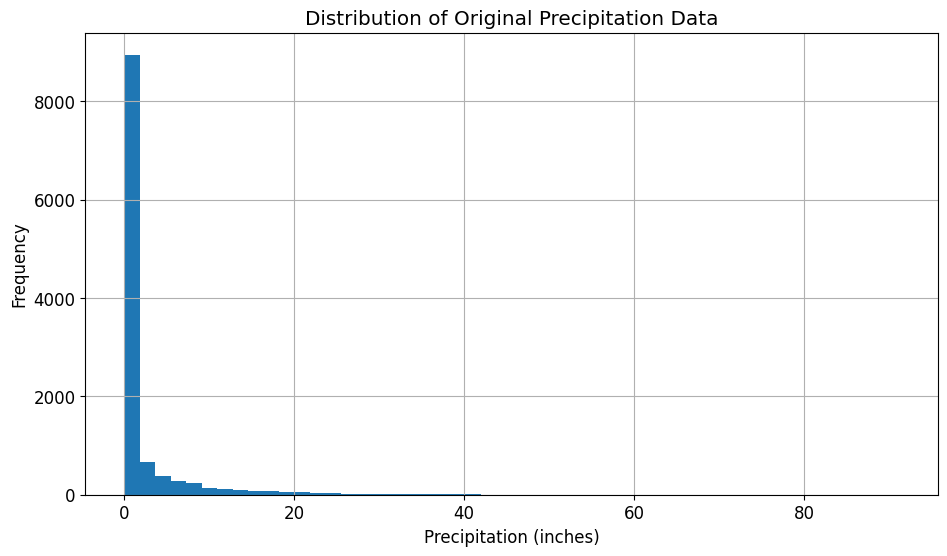


[2/5] Applying Box-Cox transformation...
✓ Box-Cox transformation complete (lambda=-1.438692)


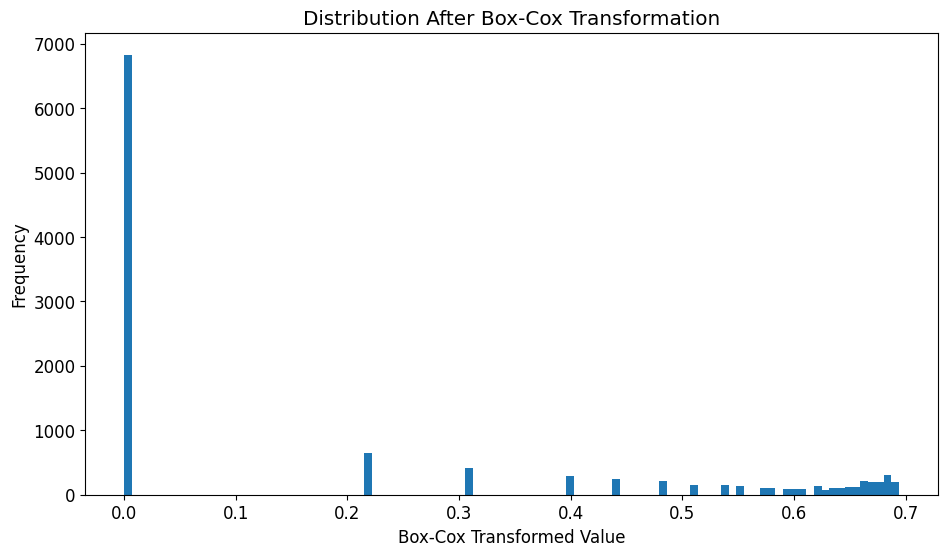


[3/5] Applying Min-Max scaling...
✓ Min-Max scaling complete
  Scaler range: [0, 1]
  Data min: 0.000000, max: 1.000093


In [7]:
# ============================================================
# TRAIN MODE: STEP 1 - LOAD AND PREPROCESS TRAINING DATA
# ============================================================

# These defaults keep this cell runnable independently in VS Code. The configuration cell overrides them when it has been run.
PLOT_TRAINING_HISTORY = globals().get('PLOT_TRAINING_HISTORY', True)
PLOT_PREDICTIONS = globals().get('PLOT_PREDICTIONS', True)

if MODE == "train":
    print(f"\n{'='*70}")
    print("TRAINING MODE: Loading and preprocessing data")
    print(f"{'='*70}")
    
    # Load training dataset
    print("\n[1/5] Loading training dataset...")
    csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
    if csv_path is None:
        raise FileNotFoundError(
            f"Could not find training data. Searched for: {TRAIN_DATA_CANDIDATES}\n"
            f"Please ensure one of these files exists in the workspace."
        )
    
    rainfall = pd.read_csv(csv_path)
    rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
    rainfall = rainfall.set_index('DATE')
    print(f"✓ Loaded {len(rainfall)} records from {csv_path}")
    print(f"  Columns: {list(rainfall.columns)}")
    print(f"  Date range: {rainfall.index[0]} to {rainfall.index[-1]}")
    
    # Plot original distribution
    if PLOT_TRAINING_HISTORY:
        plt.figure(figsize=(11, 6))
        plt.rc('font', size=12)
        series = rainfall.PRCP
        series.hist(bins=50)
        plt.title('Distribution of Original Precipitation Data')
        plt.xlabel('Precipitation (inches)')
        plt.ylabel('Frequency')
        plt.show()
    
    # Box-Cox transformation
    print("\n[2/5] Applying Box-Cox transformation...")
    # Estimate Box-Cox lambda from the chronological training portion only, then apply it to all rows.
    _, lam_value = boxcox1p(rainfall.PRCP.iloc[:DATA_CUTOFF])
    inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)
    print(f"✓ Box-Cox transformation complete (lambda={lam_value:.6f})")
    
    if PLOT_TRAINING_HISTORY:
        plt.figure(figsize=(11, 6))
        plt.hist(inv_data, bins=100)
        plt.title('Distribution After Box-Cox Transformation')
        plt.xlabel('Box-Cox Transformed Value')
        plt.ylabel('Frequency')
        plt.show()
    
    # Min-Max scaling
    print("\n[3/5] Applying Min-Max scaling...")
    scaler = MinMaxScaler(feature_range=(0, 1))
    data = inv_data.reshape(-1, 1)
    scaler.fit(data[:DATA_CUTOFF])  # Fit on chronological training rows only; never on the test horizon.
    rain_data = scaler.transform(data)[:, 0]
    print(f"✓ Min-Max scaling complete")
    print(f"  Scaler range: [0, 1]")
    print(f"  Data min: {rain_data.min():.6f}, max: {rain_data.max():.6f}")

### Step 2: Prepare LSTM Sequences

In [8]:
if MODE == "train":
    print("\n[4/5] Creating LSTM sequences...")
    
    # Prepare data for LSTM
    rain_data_model = rain_data[:TOTAL_DATA_LENGTH]
    
    # Create sequences
    x_all, y_all = split_sequences(rain_data_model, LSTM_WINDOW_SIZE)
    target_indices = np.arange(LSTM_WINDOW_SIZE, len(rain_data_model))
    
    # Split into train and test based on chronological cutoff
    train_mask = target_indices < DATA_CUTOFF
    test_mask = target_indices >= DATA_CUTOFF
    
    x_train, y_train = x_all[train_mask], y_all[train_mask]
    x_test, y_test = x_all[test_mask], y_all[test_mask]
    
    # Reshape for LSTM (add channel dimension)
    x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
    x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))
    
    print(f"✓ LSTM sequences created")
    print(f"  Total samples: {len(x_all)}")
    print(f"  Train samples: {len(x_train)}")
    print(f"  Test samples: {len(x_test)}")
    print(f"  Sequence shape: ({x_train.shape[1]}, {x_train.shape[2]})")


[4/5] Creating LSTM sequences...
✓ LSTM sequences created
  Total samples: 10918
  Train samples: 8988
  Test samples: 1930
  Sequence shape: (70, 1)


### Step 3: Build and Train LSTM Model

In [9]:
if MODE == "train":
    print("\n[5/5] Training LSTM model...")
    
    # Build LSTM model
    print("  Building model architecture...")
    model = Sequential()
    model.add(LSTM(LSTM_UNITS_LAYER1, input_shape=(LSTM_WINDOW_SIZE, 1), return_sequences=True))
    model.add(Dropout(LSTM_DROPOUT))
    model.add(LSTM(LSTM_UNITS_LAYER2))
    model.add(Dropout(LSTM_DROPOUT))
    model.add(Dense(LSTM_DENSE_UNITS, activation='relu'))
    model.add(Dense(1, activation='relu'))
    
    # Compile model
    print("  Compiling model...")
    lr_schedule = tf.keras.callbacks.LearningRateScheduler(
        lambda epoch: LSTM_LEARNING_RATE * 10**(epoch / 40))
    optimizer = tf.keras.optimizers.SGD(learning_rate=LSTM_LEARNING_RATE, momentum=LSTM_MOMENTUM)
    model.compile(loss=tf.keras.losses.Huber(),
                  optimizer=optimizer,
                  metrics=["mean_squared_error"])
    
    print("\n  Model Summary:")
    model.summary()
    
    # Train model
    print(f"\n  Starting training for {LSTM_EPOCHS} epochs...")
    history = model.fit(x_train, y_train, epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH_SIZE, verbose=1,
                        validation_data=(x_train, y_train), callbacks=[lr_schedule])
    
    print("\n✓ LSTM training complete")


[5/5] Training LSTM model...
  Building model architecture...
  Compiling model...

  Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)


  Starting training for 100 epochs...
Epoch 1/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 18s 90ms/step - loss: 0.1143 - mean_squared_error: 0.2287 - val_loss: 0.1155 - val_mean_squared_error: 0.2311 - learning_rate: 1.0000e-07
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - loss: 0.1143 - mean_squared_error: 0.2286 - val_loss: 0.1155 - val_mean_squared_error: 0.2311 - learning_rate: 1.0593e-07
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - loss: 0.1143 - mean_squared_error: 0.2285 - val_loss: 0.1155 - val_mean_squared_error: 0.2311 - learning_rate: 1.1220e-07
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - loss: 0.1143 - mean_squared_error: 0.2286 - val_loss: 0.1155 - val_mean_squared_error: 0.2311 - learning_rate: 1.1885e-07
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 78ms/step - loss: 0.1143 - mean_squared_error: 0.2285 - val_loss: 0.1155 - val_mean_squared_error: 0.2311 - learning_rate: 1.2589e-07
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 80ms/step - loss: 0.1

### Step 4: Evaluate LSTM on Test Set


LSTM MODEL EVALUATION

Evaluating LSTM on test set...
Generating LSTM test predictions...

LSTM Metrics on Test Set:
  RMSE: 5.9450
  MAE:  2.2995
  R²:   -0.1397


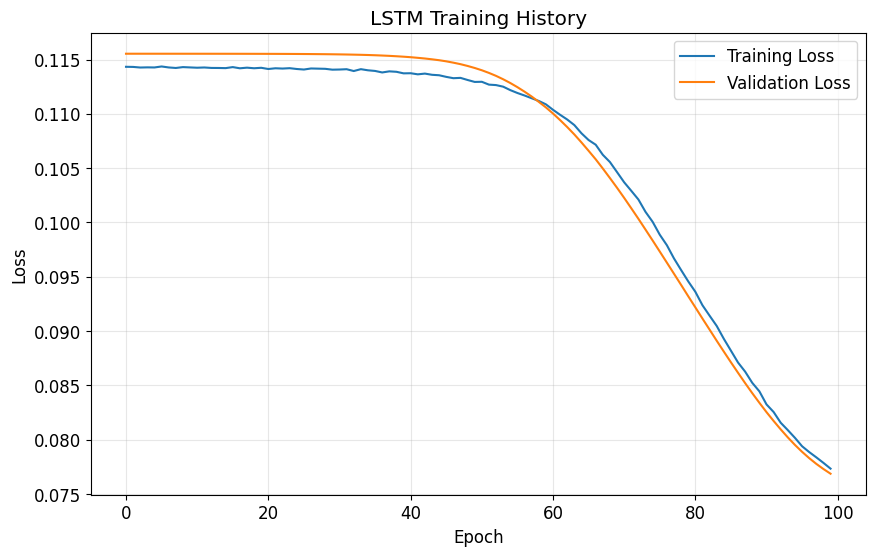


Baseline Model Comparisons:
  Average baseline RMSE: 5.9074
  Naive baseline RMSE:   7.5363


In [10]:
if MODE == "train":
    print("\n" + "="*70)
    print("LSTM MODEL EVALUATION")
    print("="*70)
    
    # Evaluate on test set
    print("\nEvaluating LSTM on test set...")
    model.evaluate(x_test, y_test, verbose=0)
    
    # Generate predictions
    print("Generating LSTM test predictions...")
    lstm_pred_scaled = model.predict(x_test, verbose=0)
    lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
    lstm_result = inv_boxcox1p(lstm_pred_bc, lam_value)
    
    # Inverse transform targets
    y_test_bc = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
    y_test_orig = inv_boxcox1p(y_test_bc, lam_value)
    y_valid = y_test_orig  # For later use in ensemble
    
    # Calculate metrics
    lstm_result = lstm_result.flatten()
    score_lstm = math.sqrt(mean_squared_error(y_valid, lstm_result))
    mae_lstm = mean_absolute_error(y_valid, lstm_result)
    r2_lstm = r2_score(y_valid, lstm_result)
    
    print(f"\nLSTM Metrics on Test Set:")
    print(f"  RMSE: {score_lstm:.4f}")
    print(f"  MAE:  {mae_lstm:.4f}")
    print(f"  R²:   {r2_lstm:.4f}")
    
    # Plot training history
    if PLOT_TRAINING_HISTORY:
        plt.figure(figsize=(10, 6))
        plt.plot(history.history['loss'], label='Training Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epoch')
        plt.title('LSTM Training History')
        plt.legend(loc='upper right')
        plt.grid(alpha=0.3)
        plt.show()
    
    # Baseline comparisons
    print("\nBaseline Model Comparisons:")
    naive_forecast_vals = naiveForecast(x_test)
    avg_forecast_vals = avgForecast(x_test)
    
    # Inverse transform baselines
    naive_forecast_vals = scaler.inverse_transform(naive_forecast_vals.reshape(-1, 1))[:, 0]
    naive_forecast_vals = inv_boxcox1p(naive_forecast_vals, lam_value)
    
    avg_forecast_vals = scaler.inverse_transform(avg_forecast_vals.reshape(-1, 1))[:, 0]
    avg_forecast_vals = inv_boxcox1p(avg_forecast_vals, lam_value)
    
    rmse_avg = math.sqrt(mean_squared_error(y_valid, avg_forecast_vals))
    rmse_naive = math.sqrt(mean_squared_error(y_valid, naive_forecast_vals))
    
    print(f"  Average baseline RMSE: {rmse_avg:.4f}")
    print(f"  Naive baseline RMSE:   {rmse_naive:.4f}")

### Step 5: Train XGBoost Models

In [11]:
if MODE == "train":
    print("\n" + "="*70)
    print("XGBOOST MODEL TRAINING")
    print("="*70)
    
    # ────────────────────────────────────────────────────────────────
    # XGBoost Feature Engineering Functions
    # ────────────────────────────────────────────────────────────────
    
    def build_xgb_feature_matrix(series, lag_window=70, rolling_windows=(7, 14), include_rolling=False):
        """Create XGBoost feature matrix from time series.
        
        Args:
            series: 1D array of values
            lag_window: Number of lag features
            rolling_windows: Tuple of rolling window sizes
            include_rolling: Whether to add rolling mean/std features
        
        Returns:
            x_array: Feature matrix
            y_array: Target array
            target_indices: Indices of targets (for train/test split)
            feature_names: List of feature names
        """
        values = np.asarray(series, dtype=float)
        start_index = max(lag_window, max(rolling_windows, default=lag_window))
        x_rows = []
        y_rows = []
        target_indices = []

        for target_index in range(start_index, len(values)):
            lag_slice = values[target_index - lag_window:target_index]
            features = list(lag_slice)

            if include_rolling:
                for window in rolling_windows:
                    trailing = values[target_index - window:target_index]
                    features.append(float(np.mean(trailing)))
                    features.append(float(np.std(trailing, ddof=0)))

            x_rows.append(features)
            y_rows.append(values[target_index])
            target_indices.append(target_index)

        x_array = np.asarray(x_rows, dtype=float)
        y_array = np.asarray(y_rows, dtype=float)
        target_indices = np.asarray(target_indices, dtype=int)

        lag_feature_names = [f'lag_{lag_window - i}' for i in range(lag_window)]
        if include_rolling:
            rolling_feature_names = []
            for window in rolling_windows:
                rolling_feature_names.extend([f'roll_mean_{window}', f'roll_std_{window}'])
            feature_names = lag_feature_names + rolling_feature_names
        else:
            feature_names = lag_feature_names

        return x_array, y_array, target_indices, feature_names

    def summarize_feature_set(x_array, y_array, target_indices, train_cutoff=9058):
        """Split feature set into train and test."""
        train_mask = target_indices < train_cutoff
        test_mask = target_indices >= train_cutoff
        x_train = x_array[train_mask]
        y_train = y_array[train_mask]
        x_test = x_array[test_mask]
        y_test = y_array[test_mask]
        return x_train, y_train, x_test, y_test

    # Prepare feature matrices
    print("\nPreparing XGBoost feature matrices...")
    model_series = np.asarray(inv_data[:TOTAL_DATA_LENGTH], dtype=float)
    print(f"  Series length: {len(model_series)}")
    print(f"  Train cutoff: {DATA_CUTOFF}")
    print(f"  Test length: {len(model_series) - DATA_CUTOFF}")
    
    # Create both feature sets
    x_lag_only, y_lag_only, idx_lag_only, lag_only_names = build_xgb_feature_matrix(
        model_series, lag_window=XGB_LAG_WINDOW, rolling_windows=XGB_ROLLING_WINDOWS,
        include_rolling=False)
    
    x_lag_roll, y_lag_roll, idx_lag_roll, lag_roll_names = build_xgb_feature_matrix(
        model_series, lag_window=XGB_LAG_WINDOW, rolling_windows=XGB_ROLLING_WINDOWS,
        include_rolling=True)
    
    # Split into train/test
    x_train_lag, y_train_lag, x_test_lag, y_test_lag = summarize_feature_set(
        x_lag_only, y_lag_only, idx_lag_only, train_cutoff=DATA_CUTOFF)
    
    x_train_roll, y_train_roll, x_test_roll, y_test_roll = summarize_feature_set(
        x_lag_roll, y_lag_roll, idx_lag_roll, train_cutoff=DATA_CUTOFF)
    
    print(f"\n  Lag-only feature set:")
    print(f"    Train samples: {x_train_lag.shape[0]}, Test samples: {x_test_lag.shape[0]}")
    print(f"    Features: {x_train_lag.shape[1]}")
    
    print(f"\n  Lag + rolling feature set:")
    print(f"    Train samples: {x_train_roll.shape[0]}, Test samples: {x_test_roll.shape[0]}")
    print(f"    Features: {x_train_roll.shape[1]}")


XGBOOST MODEL TRAINING

Preparing XGBoost feature matrices...
  Series length: 10988
  Train cutoff: 9058
  Test length: 1930

  Lag-only feature set:
    Train samples: 8988, Test samples: 1930
    Features: 70

  Lag + rolling feature set:
    Train samples: 8988, Test samples: 1930
    Features: 74


### Step 6: XGBoost Hyperparameter Tuning

In [12]:
if MODE == "train":
    print("\nTuning XGBoost models (this may take a while)...")
    
    def tune_xgb_model(x_train, y_train, x_test, y_test, lambda_value, n_iter=40, random_state=42, refine_iter=30):
        """Tune XGBoost model with grid search.
        
        Uses validation set during tuning and evaluates on test set after.
        """
        n_val = max(256, int(len(x_train) * 0.12))
        x_tr, x_val = x_train[:-n_val], x_train[-n_val:]
        y_tr, y_val = y_train[:-n_val], y_train[-n_val:]

        def to_original(values):
            values = np.asarray(values).reshape(-1)
            return inv_boxcox1p(values, lambda_value)

        y_val_orig = to_original(y_val)

        def fit_and_score(cfg):
            model_try = xgb.XGBRegressor(
                objective='reg:squarederror',
                eval_metric='rmse',
                random_state=random_state,
                n_jobs=-1,
                tree_method='hist',
                early_stopping_rounds=60,
                **cfg,
            )
            model_try.fit(
                x_tr, y_tr,
                eval_set=[(x_val, y_val)],
                verbose=False,
            )
            pred_val_orig = to_original(model_try.predict(x_val))
            rmse_val = math.sqrt(mean_squared_error(y_val_orig, pred_val_orig))
            return rmse_val, model_try

        # Initial random search
        sampled_cfgs = list(ParameterSampler(XGB_PARAM_DISTRIBUTIONS, n_iter=n_iter, random_state=random_state))

        best_val_rmse = np.inf
        best_cfg = None
        best_model = None

        for i, cfg in enumerate(sampled_cfgs):
            rmse_val, model_try = fit_and_score(cfg)
            if rmse_val < best_val_rmse:
                best_val_rmse = rmse_val
                best_cfg = cfg
                best_model = model_try
            if (i + 1) % 10 == 0:
                print(f"    Completed {i + 1}/{n_iter} iterations, best RMSE: {best_val_rmse:.4f}")

        # Refinement search
        if best_cfg is not None:
            refine_space = {
                'n_estimators': [max(200, best_cfg['n_estimators'] - 300), best_cfg['n_estimators'], min(2000, best_cfg['n_estimators'] + 300)],
                'max_depth': [max(2, best_cfg['max_depth'] - 1), best_cfg['max_depth'], min(8, best_cfg['max_depth'] + 1)],
                'learning_rate': [max(0.005, best_cfg['learning_rate'] / 1.5), best_cfg['learning_rate'], min(0.15, best_cfg['learning_rate'] * 1.5)],
                'subsample': [max(0.50, best_cfg['subsample'] - 0.10), best_cfg['subsample'], min(1.00, best_cfg['subsample'] + 0.10)],
                'colsample_bytree': [max(0.50, best_cfg['colsample_bytree'] - 0.10), best_cfg['colsample_bytree'], min(1.00, best_cfg['colsample_bytree'] + 0.10)],
                'min_child_weight': [max(1, best_cfg['min_child_weight'] - 2), best_cfg['min_child_weight'], min(12, best_cfg['min_child_weight'] + 2)],
                'gamma': [max(0.0, best_cfg['gamma'] - 0.05), best_cfg['gamma'], min(1.0, best_cfg['gamma'] + 0.05)],
                'reg_alpha': [max(0.0, best_cfg['reg_alpha'] - 0.10), best_cfg['reg_alpha'], min(1.0, best_cfg['reg_alpha'] + 0.10)],
                'reg_lambda': [max(0.5, best_cfg['reg_lambda'] / 1.5), best_cfg['reg_lambda'], min(8.0, best_cfg['reg_lambda'] * 1.5)],
            }
            refined_cfgs = list(ParameterSampler(refine_space, n_iter=refine_iter, random_state=random_state + 1))
            for i, cfg in enumerate(refined_cfgs):
                rmse_val, model_try = fit_and_score(cfg)
                if rmse_val < best_val_rmse:
                    best_val_rmse = rmse_val
                    best_cfg = cfg
                    best_model = model_try

        # Generate test predictions
        val_pred_orig = to_original(best_model.predict(x_val))
        test_pred_orig = to_original(best_model.predict(x_test))

        test_rmse = math.sqrt(mean_squared_error(to_original(y_test), test_pred_orig))
        test_mae = mean_absolute_error(to_original(y_test), test_pred_orig)
        test_r2 = r2_score(to_original(y_test), test_pred_orig)

        return {
            'best_cfg': best_cfg,
            'best_model': best_model,
            'final_model': best_model,
            'best_val_rmse': best_val_rmse,
            'val_pred_orig': val_pred_orig,
            'test_pred_orig': test_pred_orig,
            'test_rmse': test_rmse,
            'test_mae': test_mae,
            'test_r2': test_r2,
            'feature_names': None,
        }

    # Tune both feature sets
    print("\n  Tuning Lag-only model...")
    lag_only_result = tune_xgb_model(x_train_lag, y_train_lag, x_test_lag, y_test_lag, lam_value,
                                      n_iter=XGB_N_ITER_SEARCH, random_state=XGB_RANDOM_STATE,
                                      refine_iter=XGB_N_ITER_REFINE)
    lag_only_result['feature_names'] = lag_only_names
    
    print(f"\n✓ Lag-only model complete")
    print(f"  Validation RMSE: {lag_only_result['best_val_rmse']:.4f}")
    print(f"  Test RMSE: {lag_only_result['test_rmse']:.4f}")

    print("\n  Tuning Lag + Rolling model...")
    lag_roll_result = tune_xgb_model(x_train_roll, y_train_roll, x_test_roll, y_test_roll, lam_value,
                                      n_iter=XGB_N_ITER_SEARCH, random_state=XGB_RANDOM_STATE,
                                      refine_iter=XGB_N_ITER_REFINE)
    lag_roll_result['feature_names'] = lag_roll_names
    
    print(f"\n✓ Lag + Rolling model complete")
    print(f"  Validation RMSE: {lag_roll_result['best_val_rmse']:.4f}")
    print(f"  Test RMSE: {lag_roll_result['test_rmse']:.4f}")

    # Select best XGBoost model
    xgb_results = {
        'Lag only': lag_only_result,
        'Lag + rolling mean/std': lag_roll_result,
    }
    
    xgb_best_name = min(xgb_results, key=lambda name: xgb_results[name]['best_val_rmse'])
    xgb_best_result = xgb_results[xgb_best_name]
    xgb_pred_orig = xgb_best_result['test_pred_orig']
    score_xgb = xgb_best_result['test_rmse']
    mae_xgb = xgb_best_result['test_mae']
    r2_xgb = xgb_best_result['test_r2']
    xgb_model = xgb_best_result['final_model']
    best_feature_names = xgb_best_result['feature_names']

    comparison = pd.DataFrame({
        'Feature set': list(xgb_results.keys()),
        'Validation RMSE': [xgb_results[name]['best_val_rmse'] for name in xgb_results],
        'Test RMSE': [xgb_results[name]['test_rmse'] for name in xgb_results],
        'Test MAE': [xgb_results[name]['test_mae'] for name in xgb_results],
        'Test R2': [xgb_results[name]['test_r2'] for name in xgb_results],
    })

    print("\n" + "="*70)
    print("XGBOOST MODEL COMPARISON")
    print("="*70)
    print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
    print(f"\n✓ Best XGBoost strategy: {xgb_best_name}")


Tuning XGBoost models (this may take a while)...

  Tuning Lag-only model...
    Completed 10/40 iterations, best RMSE: 5.8520
    Completed 20/40 iterations, best RMSE: 5.8513
    Completed 30/40 iterations, best RMSE: 5.8513
    Completed 40/40 iterations, best RMSE: 5.8512

✓ Lag-only model complete
  Validation RMSE: 5.8498
  Test RMSE: 5.9048

  Tuning Lag + Rolling model...
    Completed 10/40 iterations, best RMSE: 5.8515
    Completed 20/40 iterations, best RMSE: 5.8515
    Completed 30/40 iterations, best RMSE: 5.8502
    Completed 40/40 iterations, best RMSE: 5.8502

✓ Lag + Rolling model complete
  Validation RMSE: 5.8502
  Test RMSE: 5.9027

XGBOOST MODEL COMPARISON
           Feature set  Validation RMSE  Test RMSE  Test MAE  Test R2
              Lag only           5.8498     5.9048    2.3048  -0.1243
Lag + rolling mean/std           5.8502     5.9027    2.3005  -0.1236

✓ Best XGBoost strategy: Lag only


### Step 7: Feature Importance Analysis


Generating feature importance plot...


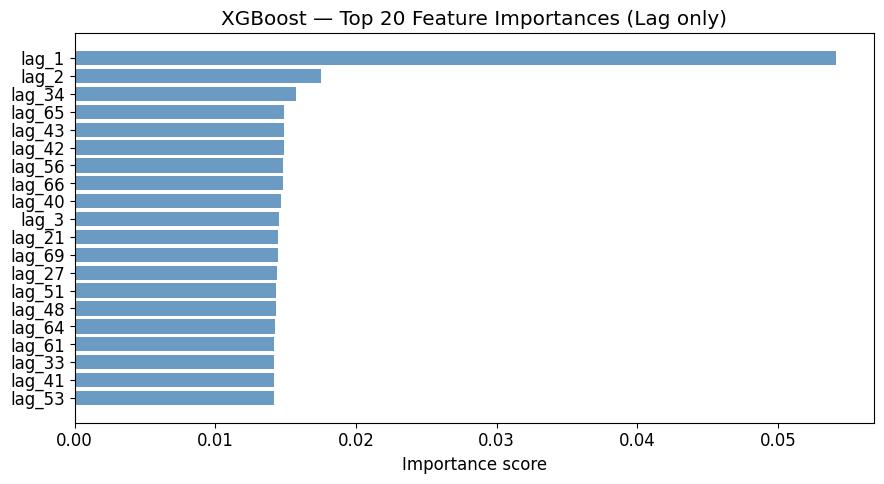

In [13]:
if MODE == "train" and PLOT_TRAINING_HISTORY:
    print("\nGenerating feature importance plot...")
    feat_imp = xgb_model.feature_importances_
    top20_idx = np.argsort(feat_imp)[-20:][::-1]
    top20_names = [best_feature_names[i] for i in top20_idx]

    plt.figure(figsize=(9, 5))
    plt.barh(top20_names[::-1], feat_imp[top20_idx[::-1]], color='steelblue', alpha=0.8)
    plt.title(f'XGBoost — Top 20 Feature Importances ({xgb_best_name})')
    plt.xlabel('Importance score')
    plt.tight_layout()
    plt.show()

### Step 8: Ensemble Method Comparison & Selection

In [14]:
if MODE == "train":
    print("\n" + "="*70)
    print("ENSEMBLE METHOD COMPARISON & SELECTION")
    print("="*70)
    
    # Prepare ensemble validation data
    print("\nPreparing ensemble validation set...")
    n_ens_val = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
    x_ens_val_lstm = x_train[-n_ens_val:]
    
    if xgb_best_name == 'Lag only':
        xgb_ens_val_matrix = x_train_lag[-n_ens_val:]
        y_ens_val_bc = y_train_lag[-n_ens_val:]
    else:
        xgb_ens_val_matrix = x_train_roll[-n_ens_val:]
        y_ens_val_bc = y_train_roll[-n_ens_val:]
    
    # Generate ensemble validation predictions
    print("Generating ensemble validation predictions...")
    lstm_val_pred_scaled = model.predict(x_ens_val_lstm, verbose=0).flatten()
    lstm_val_pred_bc = scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0]
    lstm_val_pred_orig = inv_boxcox1p(lstm_val_pred_bc, lam_value)
    
    xgb_val_pred_orig = inv_boxcox1p(xgb_best_result['final_model'].predict(xgb_ens_val_matrix), lam_value)
    y_ens_val_orig = inv_boxcox1p(y_ens_val_bc, lam_value)
    
    # Test predictions (from individual models)
    lstm_test_pred_orig = lstm_result
    xgb_test_pred_orig = xgb_pred_orig
    
    rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
    rmse_xgb_val = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))
    
    print(f"\nEnsemble Validation RMSEs:")
    print(f"  LSTM: {rmse_lstm_val:.4f}")
    print(f"  XGBoost: {rmse_xgb_val:.4f}")
    
    # 1) Simple average
    print("\nTesting ensemble methods...")
    ensemble_simple = 0.5 * lstm_test_pred_orig + 0.5 * xgb_test_pred_orig
    rmse_simple = math.sqrt(mean_squared_error(y_valid, ensemble_simple))
    
    # 2) Inverse-RMSE weighting
    inv_w_lstm = 1.0 / rmse_lstm_val
    inv_w_xgb = 1.0 / rmse_xgb_val
    inv_w_sum = inv_w_lstm + inv_w_xgb
    w_lstm_inv = inv_w_lstm / inv_w_sum
    w_xgb_inv = inv_w_xgb / inv_w_sum
    ensemble_inverse_rmse = w_lstm_inv * lstm_test_pred_orig + w_xgb_inv * xgb_test_pred_orig
    rmse_inverse = math.sqrt(mean_squared_error(y_valid, ensemble_inverse_rmse))
    
    # 3) Grid search on validation
    weight_grid = np.linspace(0.0, 1.0, 101)
    best_grid_w_lstm = 0.5
    best_grid_rmse = np.inf
    
    for w_lstm in weight_grid:
        val_mix = w_lstm * lstm_val_pred_orig + (1.0 - w_lstm) * xgb_val_pred_orig
        val_rmse = math.sqrt(mean_squared_error(y_ens_val_orig, val_mix))
        if val_rmse < best_grid_rmse:
            best_grid_rmse = val_rmse
            best_grid_w_lstm = float(w_lstm)
    
    best_grid_w_xgb = 1.0 - best_grid_w_lstm
    ensemble_grid_search = best_grid_w_lstm * lstm_test_pred_orig + best_grid_w_xgb * xgb_test_pred_orig
    rmse_grid = math.sqrt(mean_squared_error(y_valid, ensemble_grid_search))
    
    ensemble_methods = {
        'Simple average': ensemble_simple,
        'Inverse RMSE weighting': ensemble_inverse_rmse,
        'Grid-search weight': ensemble_grid_search,
    }
    
    validation_strategy_scores = {
        'Simple average': rmse_simple,
        'Inverse RMSE weighting': rmse_inverse,
        'Grid-search weight': best_grid_rmse,
    }
    
    best_strategy = min(validation_strategy_scores, key=validation_strategy_scores.get)
    ensemble_pred = ensemble_methods[best_strategy]
    score_ensemble = math.sqrt(mean_squared_error(y_valid, ensemble_pred))
    mae_ensemble = mean_absolute_error(y_valid, ensemble_pred)
    r2_ensemble = r2_score(y_valid, ensemble_pred)
    
    print(f"\nEnsemble Method Validation Scores:")
    for name, score in validation_strategy_scores.items():
        marker = " ← SELECTED" if name == best_strategy else ""
        print(f"  {name:25s}: RMSE={score:.4f}{marker}")
    
    print(f"\nEnsemble Weights:")
    print(f"  Grid-search: LSTM={best_grid_w_lstm:.2f}, XGBoost={best_grid_w_xgb:.2f}")
    print(f"  Inverse-RMSE: LSTM={w_lstm_inv:.3f}, XGBoost={w_xgb_inv:.3f}")


ENSEMBLE METHOD COMPARISON & SELECTION

Preparing ensemble validation set...
Generating ensemble validation predictions...

Ensemble Validation RMSEs:
  LSTM: 6.2164
  XGBoost: 6.1739

Testing ensemble methods...

Ensemble Method Validation Scores:
  Simple average           : RMSE=5.9243
  Inverse RMSE weighting   : RMSE=5.9242 ← SELECTED
  Grid-search weight       : RMSE=6.1739

Ensemble Weights:
  Grid-search: LSTM=0.00, XGBoost=1.00
  Inverse-RMSE: LSTM=0.498, XGBoost=0.502


### Step 8b: Precision Weight Optimization and Error Correlation Diagnostic

The grid search above already picks a good weight, but it only checks steps of 0.01. The cell below uses a continuous optimizer to find the exact minimum on the same validation set, never on the test set. After that, we check how correlated the two models' errors are, which explains how much room a weighted average actually has to help.

In [15]:
if MODE == "train":
    print("\n" + "="*70)
    print("PRECISION WEIGHT OPTIMIZATION (SCIPY)")
    print("="*70)

    from scipy.optimize import minimize_scalar

    # w* = argmin over w in [0, 1] of RMSE(w * LSTM + (1 - w) * XGBoost)
    # Solved on the validation slice only. The test set is never touched here,
    # it only gets the final weight applied once, at the very end.
    def validation_rmse_for_weight(w_lstm):
        blend = w_lstm * lstm_val_pred_orig + (1.0 - w_lstm) * xgb_val_pred_orig
        return math.sqrt(mean_squared_error(y_ens_val_orig, blend))

    opt_result = minimize_scalar(
        validation_rmse_for_weight,
        bounds=(0.0, 1.0),
        method='bounded',
        options={'xatol': 1e-4},
    )

    best_scipy_w_lstm = float(opt_result.x)
    best_scipy_w_xgb = 1.0 - best_scipy_w_lstm
    best_scipy_val_rmse = float(opt_result.fun)

    # Apply the weight to the test set exactly once, no further searching.
    ensemble_scipy_opt = best_scipy_w_lstm * lstm_test_pred_orig + best_scipy_w_xgb * xgb_test_pred_orig
    rmse_scipy_opt = math.sqrt(mean_squared_error(y_valid, ensemble_scipy_opt))

    print(f"\nOptimal weight found on the validation set:")
    print(f"  LSTM weight:    {best_scipy_w_lstm:.4f}")
    print(f"  XGBoost weight: {best_scipy_w_xgb:.4f}")
    print(f"  Validation RMSE at this weight: {best_scipy_val_rmse:.4f}")
    print(f"  Resulting test RMSE (weight applied once): {rmse_scipy_opt:.4f}")

    if abs(best_scipy_w_lstm - 0.5) < 0.03:
        print("\n  This weight lands close to 0.5, which lines up with the equal weight")
        print("  reasoning already used for the simple average method.")
    else:
        favored = "LSTM" if best_scipy_w_lstm > 0.5 else "XGBoost"
        print(f"\n  This weight leans toward {favored}, which is consistent with its")
        print(f"  lower standalone validation RMSE.")

    # Fold this method into the same selection pool as the other three, so the
    # best overall method wins on its own merits rather than being hardcoded.
    ensemble_methods['Optimized weight (scipy)'] = ensemble_scipy_opt
    validation_strategy_scores['Optimized weight (scipy)'] = best_scipy_val_rmse

    best_strategy = min(validation_strategy_scores, key=validation_strategy_scores.get)
    ensemble_pred = ensemble_methods[best_strategy]
    score_ensemble = math.sqrt(mean_squared_error(y_valid, ensemble_pred))
    mae_ensemble = mean_absolute_error(y_valid, ensemble_pred)
    r2_ensemble = r2_score(y_valid, ensemble_pred)

    print(f"\nUpdated selection after adding the scipy optimized weight:")
    for name, score in validation_strategy_scores.items():
        marker = " <- SELECTED" if name == best_strategy else ""
        print(f"  {name:28s}: RMSE={score:.4f}{marker}")



PRECISION WEIGHT OPTIMIZATION (SCIPY)

Optimal weight found on the validation set:
  LSTM weight:    0.0001
  XGBoost weight: 0.9999
  Validation RMSE at this weight: 6.1739
  Resulting test RMSE (weight applied once): 5.9048

  This weight leans toward XGBoost, which is consistent with its
  lower standalone validation RMSE.

Updated selection after adding the scipy optimized weight:
  Simple average              : RMSE=5.9243
  Inverse RMSE weighting      : RMSE=5.9242 <- SELECTED
  Grid-search weight          : RMSE=6.1739
  Optimized weight (scipy)    : RMSE=6.1739



ERROR CORRELATION DIAGNOSTIC

Validation set error correlation between LSTM and XGBoost: 0.9997
  This is a high correlation. The two models are largely missing on
  the same days, in the same direction, which limits how much any
  weighted average can improve over the stronger individual model.

Test set error correlation (for reporting in results): 0.9997


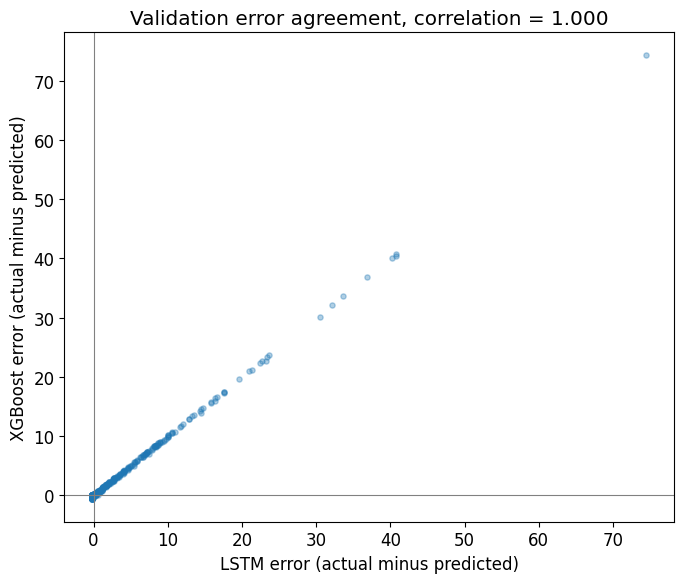

In [16]:
if MODE == "train":
    print("\n" + "="*70)
    print("ERROR CORRELATION DIAGNOSTIC")
    print("="*70)

    # This checks whether LSTM and XGBoost tend to miss on the same days.
    # If the two error series move together, averaging them still leaves
    # a similar wrong answer, since both models are wrong in the same place
    # at the same time. This is the main thing that limits how far a
    # weighted average can push the RMSE down.
    lstm_val_errors = y_ens_val_orig - lstm_val_pred_orig
    xgb_val_errors = y_ens_val_orig - xgb_val_pred_orig
    error_correlation = float(np.corrcoef(lstm_val_errors, xgb_val_errors)[0, 1])

    print(f"\nValidation set error correlation between LSTM and XGBoost: {error_correlation:.4f}")

    if error_correlation >= 0.90:
        print("  This is a high correlation. The two models are largely missing on")
        print("  the same days, in the same direction, which limits how much any")
        print("  weighted average can improve over the stronger individual model.")
    elif error_correlation >= 0.70:
        print("  This is a moderate to high correlation. Some complementary signal")
        print("  exists, but a large share of the error is shared between models.")
    else:
        print("  This is a comparatively low correlation. The models are making")
        print("  different mistakes on different days, which is the condition")
        print("  under which ensembling helps the most.")

    # Also compute it on the test set, useful for reporting in the results section
    # since it reflects the same data the final RMSE numbers come from.
    lstm_test_errors = y_valid - lstm_test_pred_orig
    xgb_test_errors = y_valid - xgb_test_pred_orig
    test_error_correlation = float(np.corrcoef(lstm_test_errors, xgb_test_errors)[0, 1])
    print(f"\nTest set error correlation (for reporting in results): {test_error_correlation:.4f}")

    if PLOT_TRAINING_HISTORY:
        plt.figure(figsize=(7, 6))
        plt.scatter(lstm_val_errors, xgb_val_errors, alpha=0.35, s=14)
        plt.axhline(0, color='gray', linewidth=0.8)
        plt.axvline(0, color='gray', linewidth=0.8)
        plt.xlabel('LSTM error (actual minus predicted)')
        plt.ylabel('XGBoost error (actual minus predicted)')
        plt.title(f'Validation error agreement, correlation = {error_correlation:.3f}')
        plt.tight_layout()
        plt.show()


### Step 9: Final Comparison and Evaluation

In [17]:
if MODE == "train":
    print("\n" + "="*70)
    print("FINAL MODEL COMPARISON")
    print("="*70)
    
    comparison_rows = [
        ('LSTM (baseline)', score_lstm, mae_lstm, r2_lstm),
        ('XGBoost (standalone)', score_xgb, mae_xgb, r2_xgb),
        ('Simple average', rmse_simple, mean_absolute_error(y_valid, ensemble_simple), r2_score(y_valid, ensemble_simple)),
        ('Inverse RMSE weighting', rmse_inverse, mean_absolute_error(y_valid, ensemble_inverse_rmse), r2_score(y_valid, ensemble_inverse_rmse)),
        ('Grid-search weight', rmse_grid, mean_absolute_error(y_valid, ensemble_grid_search), r2_score(y_valid, ensemble_grid_search)),
        ('Optimized weight (scipy)', rmse_scipy_opt, mean_absolute_error(y_valid, ensemble_scipy_opt), r2_score(y_valid, ensemble_scipy_opt)),
        (f'Selected ensemble ({best_strategy})', score_ensemble, mae_ensemble, r2_ensemble),
    ]
    
    df_summary = pd.DataFrame(comparison_rows, columns=['Model', 'RMSE', 'MAE', 'R2'])
    df_summary = df_summary.sort_values('RMSE', ascending=True).reset_index(drop=True)
    
    print(f"\n{df_summary.to_string(index=False, float_format=lambda x: f'{x:.4f}')}")
    
    best_model_name = df_summary.iloc[0]['Model']
    best_rmse = df_summary.iloc[0]['RMSE']
    print(f"\n✓ Best method by RMSE: {best_model_name} ({best_rmse:.4f})")


FINAL MODEL COMPARISON

                                     Model   RMSE    MAE      R2
                      XGBoost (standalone) 5.9048 2.3048 -0.1243
                        Grid-search weight 5.9048 2.3048 -0.1243
                  Optimized weight (scipy) 5.9048 2.3048 -0.1243
                    Inverse RMSE weighting 5.9242 2.2994 -0.1318
Selected ensemble (Inverse RMSE weighting) 5.9242 2.2994 -0.1318
                            Simple average 5.9243 2.2994 -0.1318
                           LSTM (baseline) 5.9450 2.2995 -0.1397

✓ Best method by RMSE: XGBoost (standalone) (5.9048)


### Step 10: Visualization


Generating forecast comparison plot...


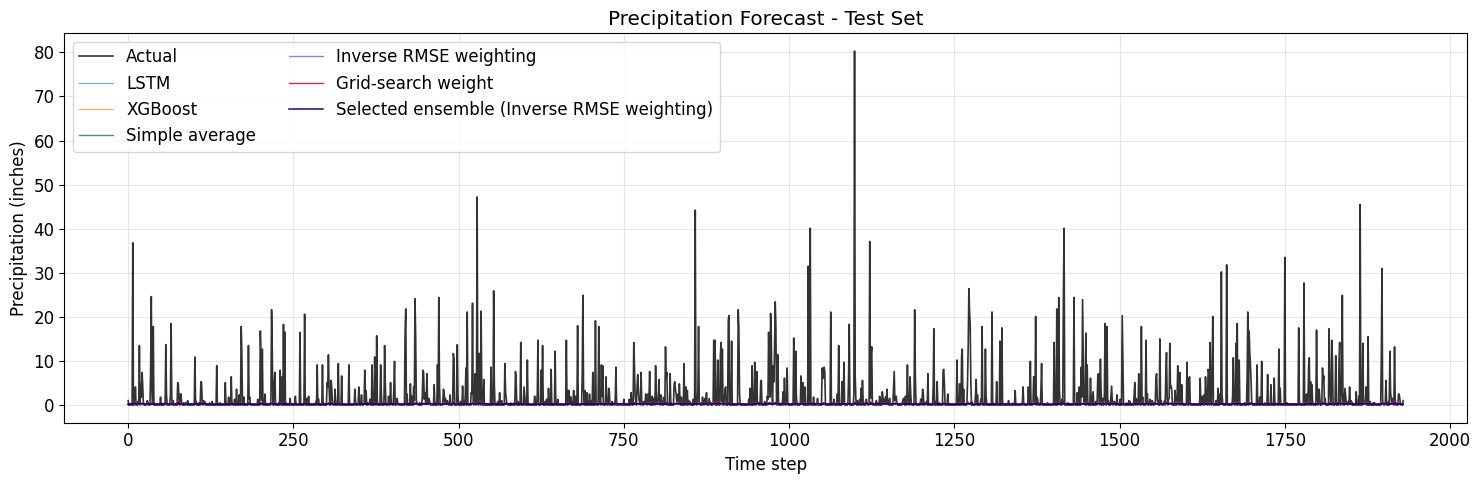


Generating RMSE comparison bar chart...


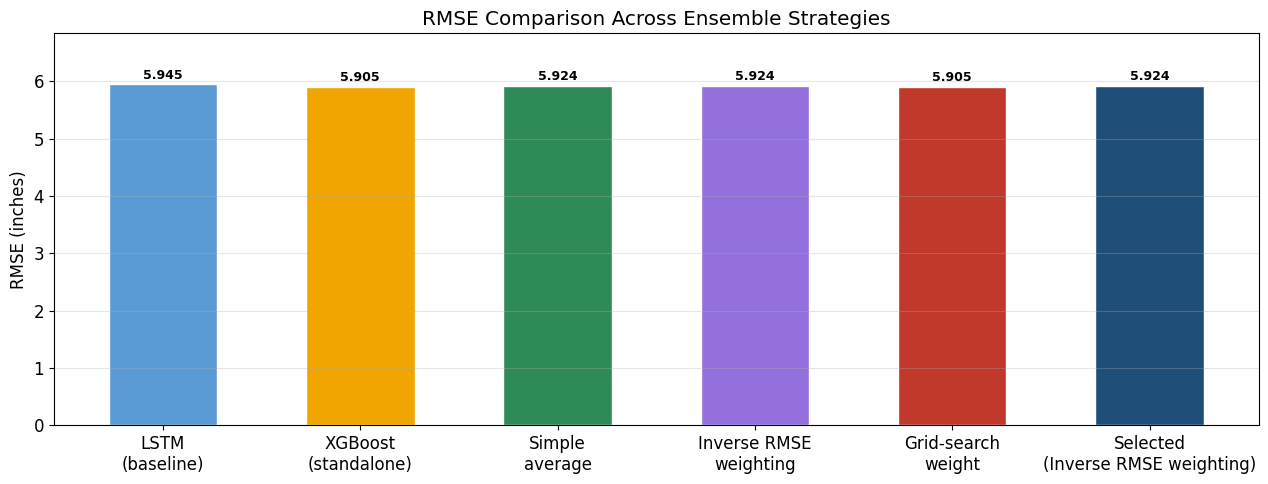

In [18]:
if MODE == "train" and PLOT_PREDICTIONS:
    print("\nGenerating forecast comparison plot...")
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(y_valid, label='Actual', color='black', linewidth=1.2, alpha=0.8)
    ax.plot(lstm_result, label='LSTM', color='steelblue', linewidth=0.8, alpha=0.7)
    ax.plot(xgb_pred_orig, label='XGBoost', color='darkorange', linewidth=0.8, alpha=0.7)
    ax.plot(ensemble_simple, label='Simple average', color='seagreen', linewidth=1.0, alpha=0.9)
    ax.plot(ensemble_inverse_rmse, label='Inverse RMSE weighting', color='mediumpurple', linewidth=1.0, alpha=0.9)
    ax.plot(ensemble_grid_search, label='Grid-search weight', color='crimson', linewidth=1.0, alpha=0.9)
    ax.plot(ensemble_pred, label=f'Selected ensemble ({best_strategy})', color='navy', linewidth=1.1, alpha=0.95)
    ax.set_title('Precipitation Forecast - Test Set')
    ax.set_xlabel('Time step')
    ax.set_ylabel('Precipitation (inches)')
    ax.legend(ncol=2)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print("\nGenerating RMSE comparison bar chart...")
    models = [
        'LSTM\n(baseline)',
        'XGBoost\n(standalone)',
        'Simple\naverage',
        'Inverse RMSE\nweighting',
        'Grid-search\nweight',
        f'Selected\n({best_strategy})',
    ]
    rmses = [
        score_lstm,
        score_xgb,
        rmse_simple,
        rmse_inverse,
        rmse_grid,
        score_ensemble,
    ]
    colors = ['#5b9bd5', '#f0a500', '#2e8b57', '#9370db', '#c0392b', '#1f4e79']
    
    fig, ax = plt.subplots(figsize=(13, 5))
    bars = ax.bar(models, rmses, color=colors, edgecolor='white', width=0.55)
    for bar, val in zip(bars, rmses):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title('RMSE Comparison Across Ensemble Strategies')
    ax.set_ylabel('RMSE (inches)')
    ax.set_ylim(0, max(rmses) * 1.15)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

### Step 11: Save Trained Models and Preprocessing Objects

In [19]:
if MODE == "train":
    print("\n" + "="*70)
    print("SAVING TRAINED MODELS AND ARTIFACTS")
    print("="*70)
    
    # Save LSTM model
    print(f"\nSaving LSTM model...")
    model.save(LSTM_MODEL_PATH)
    print(f"✓ LSTM saved to {LSTM_MODEL_PATH}")
    
    # Save XGBoost model
    print(f"Saving XGBoost model...")
    joblib.dump(xgb_model, XGB_MODEL_PATH)
    print(f"✓ XGBoost saved to {XGB_MODEL_PATH}")
    
    # Save MinMax scaler
    print(f"Saving MinMax scaler...")
    joblib.dump(scaler, MINMAX_SCALER_PATH)
    print(f"✓ Scaler saved to {MINMAX_SCALER_PATH}")
    
    # Save metadata
    print(f"Saving metadata...")
    metadata = {
        "model_type": "LSTM_XGBoost_Ensemble",
        "training_version": "1.0",
        "lstm_config": {
            "window_size": LSTM_WINDOW_SIZE,
            "units_layer1": LSTM_UNITS_LAYER1,
            "units_layer2": LSTM_UNITS_LAYER2,
            "dense_units": LSTM_DENSE_UNITS,
            "dropout": LSTM_DROPOUT,
            "epochs": LSTM_EPOCHS,
            "batch_size": LSTM_BATCH_SIZE,
            "learning_rate": float(LSTM_LEARNING_RATE),
            "momentum": LSTM_MOMENTUM,
        },
        "xgboost_config": {
            "feature_strategy": xgb_best_name,
            "lag_window": XGB_LAG_WINDOW,
            "rolling_windows": list(XGB_ROLLING_WINDOWS),
            "feature_names": best_feature_names,
            "best_parameters": xgb_best_result['best_cfg'],
        },
        "preprocessing": {
            "box_cox_lambda": float(lam_value),
            "scaler_type": "MinMaxScaler",
            "scaler_range": [0, 1],
        },
        "data_split": {
            "cutoff_index": DATA_CUTOFF,
            "total_length": TOTAL_DATA_LENGTH,
            "lstm_train_samples": len(x_train),
            "lstm_test_samples": len(x_test),
        },
        "ensemble": {
            "best_strategy": best_strategy,
            "grid_weights": {
                "lstm": float(best_grid_w_lstm),
                "xgboost": float(best_grid_w_xgb),
            },
            "inverse_rmse_weights": {
                "lstm": float(w_lstm_inv),
                "xgboost": float(w_xgb_inv),
            },
            "scipy_optimized_weights": {
                "lstm": float(best_scipy_w_lstm),
                "xgboost": float(best_scipy_w_xgb),
                "validation_rmse": float(best_scipy_val_rmse),
            },
            "error_correlation": {
                "validation": float(error_correlation),
                "test": float(test_error_correlation),
            },
        },
        "evaluation": {
            "lstm_rmse": float(score_lstm),
            "xgboost_rmse": float(score_xgb),
            "ensemble_rmse": float(score_ensemble),
            "ensemble_mae": float(mae_ensemble),
            "ensemble_r2": float(r2_ensemble),
        },
    }
    
    save_metadata(metadata, METADATA_PATH)
    
    print(f"\n✓ All models and preprocessing objects saved successfully!")
    print(f"\nArtifacts saved:")
    print(f"  • {LSTM_MODEL_PATH}")
    print(f"  • {XGB_MODEL_PATH}")
    print(f"  • {MINMAX_SCALER_PATH}")
    print(f"  • {METADATA_PATH}")


SAVING TRAINED MODELS AND ARTIFACTS

Saving LSTM model...
✓ LSTM saved to models\v1/lstm_model.keras
Saving XGBoost model...
✓ XGBoost saved to models\v1/xgb_model.pkl
Saving MinMax scaler...
✓ Scaler saved to models\v1/minmax_scaler.pkl
Saving metadata...
✓ Metadata saved to models\v1/metadata.json

✓ All models and preprocessing objects saved successfully!

Artifacts saved:
  • models\v1/lstm_model.keras
  • models\v1/xgb_model.pkl
  • models\v1/minmax_scaler.pkl
  • models\v1/metadata.json


---
## MODE: PREDICT

### Load Trained Models and Prepare New Data

In [20]:
if MODE == "predict":
    print(f"\n{'='*70}")
    print("PREDICTION MODE: Loading models and making predictions")
    print(f"{'='*70}")
    
    # ────────────────────────────────────────────────────────────────
    # PREDICT: Step 1 - Load Models and Preprocessing Objects
    # ────────────────────────────────────────────────────────────────
    
    print("\n[1/4] Loading trained models and preprocessing objects...")
    
    # Check if model files exist
    required_files = [
        (LSTM_MODEL_PATH, "LSTM model"),
        (XGB_MODEL_PATH, "XGBoost model"),
        (MINMAX_SCALER_PATH, "MinMax scaler"),
        (METADATA_PATH, "Metadata"),
    ]
    
    missing_files = [f for f, _ in required_files if not Path(f).exists()]
    
    if missing_files:
        error_msg = "\n".join([f"  • {f}" for f in missing_files])
        raise FileNotFoundError(
            f"\nError: Trained model files not found:\n{error_msg}\n\n"
            f"Please run the notebook with MODE = 'train' first to train and save the models.\n\n"
            f"Procedure:\n"
            f"  1. Set MODE = 'train'\n"
            f"  2. Run all cells\n"
            f"  3. Models will be saved to the 'models/' directory\n"
            f"  4. Then set MODE = 'predict' and run prediction\n"
        )
    
    # Load models
    print("  Loading LSTM model...")
    model = load_model(LSTM_MODEL_PATH)
    print("  ✓ LSTM loaded")
    
    print("  Loading XGBoost model...")
    xgb_model = joblib.load(XGB_MODEL_PATH)
    print("  ✓ XGBoost loaded")
    
    print("  Loading MinMax scaler...")
    scaler = joblib.load(MINMAX_SCALER_PATH)
    print("  ✓ Scaler loaded")
    
    print("  Loading metadata...")
    metadata = load_metadata(METADATA_PATH)
    print("  ✓ Metadata loaded")
    
    # Extract configuration from metadata
    lam_value = metadata['preprocessing']['box_cox_lambda']
    lstm_window = metadata['lstm_config']['window_size']
    xgb_lag_window = metadata['xgboost_config']['lag_window']
    xgb_rolling_windows = tuple(metadata['xgboost_config']['rolling_windows'])
    xgb_best_name = metadata['xgboost_config']['feature_strategy']
    best_strategy = metadata['ensemble']['best_strategy']
    best_grid_w_lstm = metadata['ensemble']['grid_weights']['lstm']
    best_grid_w_xgb = metadata['ensemble']['grid_weights']['xgboost']
    w_lstm_inv = metadata['ensemble']['inverse_rmse_weights']['lstm']
    w_xgb_inv = metadata['ensemble']['inverse_rmse_weights']['xgboost']
    best_scipy_w_lstm = metadata['ensemble']['scipy_optimized_weights']['lstm']
    best_scipy_w_xgb = metadata['ensemble']['scipy_optimized_weights']['xgboost']
    
    print(f"\n✓ All models loaded successfully")
    print(f"  LSTM window: {lstm_window}")
    print(f"  XGBoost features: {xgb_best_name}")
    print(f"  Ensemble strategy: {best_strategy}")

### Load New Data for Prediction

In [21]:
if MODE == "predict":
    print("\n[2/4] Loading new dataset...")
    
    # Load new data
    if not Path(NEW_DATA_PATH).exists():
        raise FileNotFoundError(
            f"\nNew data file not found: {NEW_DATA_PATH}\n\n"
            f"Please change NEW_DATA_PATH to point to your new precipitation data file.\n\n"
            f"Expected format: CSV with 'DATE' and 'PRCP' columns\n"
        )
    
    new_rainfall = pd.read_csv(NEW_DATA_PATH)
    missing_columns = {'DATE', 'PRCP'} - set(new_rainfall.columns)
    if missing_columns:
        raise ValueError(f"Prediction data is missing required column(s): {sorted(missing_columns)}. This univariate model requires observed PRCP history as input.")
    if new_rainfall['PRCP'].isna().any():
        raise ValueError("PRCP contains missing values. Provide at least the complete observed history required for one-step forecasts; recursive multi-step forecasting is not part of this trained model.")
    new_rainfall["DATE"] = pd.to_datetime(new_rainfall["DATE"], dayfirst=True)
    new_rainfall = new_rainfall.set_index('DATE').sort_index()
    if new_rainfall.index.has_duplicates:
        raise ValueError("DATE values must be unique for time-series prediction.")
    xgb_feature_start = max(xgb_lag_window, max(xgb_rolling_windows, default=xgb_lag_window))
    prediction_start_idx = max(lstm_window, xgb_feature_start)
    if len(new_rainfall) <= prediction_start_idx:
        raise ValueError(f"Insufficient historical observations: need more than {prediction_start_idx} rows, received {len(new_rainfall)}.")
    
    print(f"✓ Loaded {len(new_rainfall)} records from {NEW_DATA_PATH}")
    print(f"  Date range: {new_rainfall.index[0]} to {new_rainfall.index[-1]}")
    
    # ────────────────────────────────────────────────────────────────
    # PREDICT: Step 2 - Preprocess New Data
    # ────────────────────────────────────────────────────────────────
    
    print("\n[3/4] Preprocessing new data...")
    
    # Apply Box-Cox transformation (using saved lambda)
    print("  Applying Box-Cox transformation...")
    new_p1data = new_rainfall.PRCP.to_numpy() + 1
    new_inv_data = boxcox(new_p1data, lmbda=lam_value)  # Apply the saved lambda; do not estimate it again.
    
    print(f"  ✓ Box-Cox transformation applied (lambda={lam_value:.6f})")
    
    # Apply Min-Max scaling (using saved scaler - TRANSFORM ONLY, DO NOT FIT)
    print("  Applying Min-Max scaling (using saved scaler)...")
    new_data_reshaped = new_inv_data.reshape(-1, 1)
    new_rain_data = scaler.transform(new_data_reshaped)[:, 0]  # Transform only, never fit!
    print(f"  ✓ Min-Max scaling applied")
    
    # ────────────────────────────────────────────────────────────────
    # PREDICT: Step 3 - Create Sequences and Generate Predictions
    # ────────────────────────────────────────────────────────────────
    
    print("\n[4/4] Generating predictions...")
    
    # Create LSTM sequences from new data
    print("  Creating LSTM sequences...")
    x_pred_all, _ = split_sequences(new_rain_data, lstm_window)
    # Select by target timestamp so both branches begin at the same observation.
    lstm_target_indices = np.arange(lstm_window, len(new_rain_data))
    common_target_indices = np.arange(prediction_start_idx, len(new_rain_data))
    x_pred_lstm = x_pred_all[np.isin(lstm_target_indices, common_target_indices)]
    x_pred_lstm = np.reshape(x_pred_lstm, (x_pred_lstm.shape[0], x_pred_lstm.shape[1], 1))
    print(f"  ✓ Created {len(x_pred_lstm)} LSTM sequences")
    
    # Generate LSTM predictions
    print("  Generating LSTM predictions...")
    lstm_pred_scaled = model.predict(x_pred_lstm, verbose=0)
    lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
    lstm_pred_orig = inv_boxcox1p(lstm_pred_bc, lam_value)
    print(f"  ✓ Generated {len(lstm_pred_orig)} LSTM predictions")
    
    # Create XGBoost features from new data
    print("  Creating XGBoost features...")
    
    def build_xgb_feature_matrix_predict(series, lag_window=70, rolling_windows=(7, 14), include_rolling=False):
        """Create XGBoost feature matrix (prediction version - no train/test split)."""
        values = np.asarray(series, dtype=float)
        start_index = max(lag_window, max(rolling_windows, default=lag_window))
        x_rows = []

        for target_index in range(start_index, len(values)):
            lag_slice = values[target_index - lag_window:target_index]
            features = list(lag_slice)

            if include_rolling:
                for window in rolling_windows:
                    trailing = values[target_index - window:target_index]
                    features.append(float(np.mean(trailing)))
                    features.append(float(np.std(trailing, ddof=0)))

            x_rows.append(features)

        return np.asarray(x_rows, dtype=float)
    
    include_rolling_pred = (xgb_best_name == 'Lag + rolling mean/std')
    x_pred_xgb_all = build_xgb_feature_matrix_predict(
        new_inv_data, lag_window=xgb_lag_window, rolling_windows=xgb_rolling_windows,
        include_rolling=include_rolling_pred
    )
    # Select the same target timestamps as LSTM; this is index alignment, not arbitrary truncation.
    x_pred_xgb = x_pred_xgb_all[prediction_start_idx - xgb_feature_start:]
    print(f"  ✓ Created {len(x_pred_xgb)} XGBoost feature vectors")
    
    # Check alignment
    if len(lstm_pred_orig) != len(x_pred_xgb):
        raise ValueError(
            f"\nPrediction alignment error:\n"
            f"  LSTM predictions: {len(lstm_pred_orig)}\n"
            f"  XGBoost features: {len(x_pred_xgb)}\n\n"
            f"This suggests a mismatch in sequence creation. "
            f"Both should have the same number of samples."
        )
    
    # Generate XGBoost predictions
    print("  Generating XGBoost predictions...")
    xgb_pred_bc = xgb_model.predict(x_pred_xgb)
    xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)
    print(f"  ✓ Generated {len(xgb_pred_orig)} XGBoost predictions")
    
    # Generate ensemble predictions
    print("  Generating ensemble predictions...")
    if best_strategy == 'Simple average':
        ensemble_pred = 0.5 * lstm_pred_orig + 0.5 * xgb_pred_orig
    elif best_strategy == 'Inverse RMSE weighting':
        ensemble_pred = w_lstm_inv * lstm_pred_orig + w_xgb_inv * xgb_pred_orig
    elif best_strategy == 'Grid-search weight':
        ensemble_pred = best_grid_w_lstm * lstm_pred_orig + best_grid_w_xgb * xgb_pred_orig
    elif best_strategy == 'Optimized weight (scipy)':
        ensemble_pred = best_scipy_w_lstm * lstm_pred_orig + best_scipy_w_xgb * xgb_pred_orig
    else:
        raise ValueError(f"Unknown ensemble strategy: {best_strategy}")
    
    print(f"  ✓ Generated {len(ensemble_pred)} ensemble predictions using {best_strategy}")

### Save Predictions

In [22]:
if MODE == "predict":
    print("\n" + "="*70)
    print("SAVING PREDICTIONS")
    print("="*70)
    
    # Create results dataframe
    # Note: predictions start at index lstm_window because we need that many historical observations
    prediction_dates = new_rainfall.index[prediction_start_idx:prediction_start_idx + len(ensemble_pred)]
    
    results_df = pd.DataFrame({
        'DATE': prediction_dates,
        'LSTM_prediction': lstm_pred_orig,
        'XGBoost_prediction': xgb_pred_orig,
        'Ensemble_prediction': ensemble_pred,
    })
    
    # Add actual values if available in new data
    if 'PRCP' in new_rainfall.columns:
        results_df['Actual_precipitation'] = new_rainfall['PRCP'].iloc[prediction_start_idx:prediction_start_idx + len(ensemble_pred)].values
        print("\nActual precipitation values included in output.")
    else:
        print("\nNote: Actual precipitation not available in new data (prediction-only mode).")
    
    # Save to CSV
    results_df.to_csv(PREDICTION_OUTPUT_PATH, index=False)
    print(f"\n✓ Predictions saved to {PREDICTION_OUTPUT_PATH}")
    print(f"  Total predictions: {len(results_df)}")
    print(f"  Date range: {results_df['DATE'].min()} to {results_df['DATE'].max()}")
    print(f"\nFirst 10 predictions:")
    print(results_df.head(10).to_string(index=False))
    print(f"\nSummary statistics:")
    print(results_df[['LSTM_prediction', 'XGBoost_prediction', 'Ensemble_prediction']].describe())

### Prediction Visualization

In [23]:
if MODE == "predict" and PLOT_PREDICTIONS:
    print("\nGenerating prediction plots...")
    
    fig, ax = plt.subplots(figsize=(15, 5))
    
    ax.plot(results_df['DATE'], lstm_pred_orig, label='LSTM', color='steelblue', linewidth=1.0, alpha=0.8)
    ax.plot(results_df['DATE'], xgb_pred_orig, label='XGBoost', color='darkorange', linewidth=1.0, alpha=0.8)
    ax.plot(results_df['DATE'], ensemble_pred, label=f'Ensemble ({best_strategy})', color='crimson', linewidth=1.2, alpha=0.9)
    
    if 'Actual_precipitation' in results_df.columns:
        ax.plot(results_df['DATE'], results_df['Actual_precipitation'], label='Actual', color='black', linewidth=1.2, alpha=0.8)
    
    ax.set_title('Precipitation Forecast - New Data Predictions')
    ax.set_xlabel('Date')
    ax.set_ylabel('Precipitation (inches)')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

---
## Pipeline Complete

### Summary

#### Training Mode (MODE = "train")
- Loaded and preprocessed historical precipitation data
- Applied Box-Cox transformation and Min-Max scaling
- Trained LSTM neural network (2 layers, 32 units each, dropout regularization)
- Trained and tuned XGBoost with grid search (compared lag-only vs lag+rolling features)
- Compared four ensemble methods: simple average, inverse-RMSE weighting, grid-search weights, and a scipy-optimized weight
- Selected the best-performing ensemble method based on validation RMSE only, the test set is used once at the end for reporting
- Measured the error correlation between LSTM and XGBoost to explain the ensemble's ceiling
- Saved all models, scalers, and metadata for reproducible prediction

#### Prediction Mode (MODE = "predict")
- Loaded previously trained LSTM and XGBoost models
- Loaded preprocessing objects (scaler and Box-Cox lambda)
- Applied identical preprocessing to new data
- Generated predictions from both LSTM and XGBoost
- Combined predictions using the learned ensemble method
- Saved results with timestamps

### Important Notes

1. **No Retraining in Prediction Mode**: The prediction pipeline only uses `.transform()` on the scaler, never `.fit()`. Models are loaded as-is and used for inference only.

2. **Time Series Lookback**: Predictions start at index 70 (the LSTM window size) because each LSTM sequence requires 70 historical observations.

3. **Preprocessing Consistency**: The exact Box-Cox lambda value and scaler statistics from training are reused in prediction to ensure consistency.

4. **Data Alignment**: LSTM and XGBoost predictions are aligned by construction—both use the same preprocessing and lookback logic.

5. **To Retrain**: Change `MODE = "train"`, optionally update hyperparameters, and run the notebook. New models will overwrite existing ones.